# ConectaMap — Pré-processamento dos dados
**Global Solution FIAP 2026.2 · CitizenTech**

Este notebook vai dos arquivos brutos da Anatel e do IBGE até as bases tratadas que serão usadas na etapa de modelagem:

**dados brutos → limpeza e padronização → organização temporal → verificações de qualidade → sinalização de anomalias → bases finais**

## 1. Introdução
O **ConectaMap** busca identificar municípios brasileiros com risco de permanecer com baixa densidade de banda larga fixa nos próximos anos, para apoiar a priorização de políticas públicas de inclusão digital.

A banda larga fixa é a principal forma de acesso estável à internet nos domicílios e está ligada a educação, trabalho e acesso a serviços públicos. A distribuição desse acesso é muito desigual entre os municípios.

**Fontes utilizadas**
- **Anatel**: densidade de acessos de banda larga fixa por 100 domicílios, por município e competência (2007 a 2026).
- **IBGE — Censo Demográfico 2022**: cinco tabelas do SIDRA com características dos municípios (população urbana e rural, idade, saneamento, renda e deficiência).

**Objetivo do pré-processamento:** padronizar e organizar as fontes, verificar a qualidade dos dados e sinalizar observações atípicas **sem alterar os valores publicados**, gerando bases rastreáveis para a etapa seguinte. Modelos, alvo de previsão e features não fazem parte deste notebook.

A lógica de processamento fica no pacote `conectamap/`, para que este notebook mostre as etapas sem blocos longos de código:

| Módulo | Função |
|---|---|
| `config.py` | Caminhos, nomes dos arquivos e parâmetros |
| `fontes.py` | Leitura e conversão dos arquivos da Anatel e do SIDRA |
| `anomalias.py` | Organização município × mês e detecção retrospectiva de episódios atípicos (regra D) |
| `series.py` | Séries original, retrospectiva e causal; sinalização causal |
| `calibracao.py` | Identificação de meses ausentes (entre outras análises técnicas) |
| `preparacao.py` | Funções de apoio deste notebook: resumos, montagem e exportação das bases |

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path(".").resolve()))   # pasta do projeto, onde está o pacote conectamap/
from conectamap import anomalias as AN, config as C, fontes as F, preparacao as PP, series as S

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

LIMITE = C.PARAMETROS_APROVADOS["limite_observacao"]          # último mês usado no processamento
INICIO_MENSAL = C.PARAMETROS_APROVADOS["inicio_periodo_mensal"]
PARAMS = dict(C.PARAMETROS_CANDIDATOS)                        # regra D de referência (K=5, A=10, L=12)
PARAMS_L6 = dict(PARAMS, L=6)                                  # configuração alternativa (sensibilidade)

print(f"Limite de observação: {LIMITE} | período mensal a partir de {INICIO_MENSAL} | "
      f"regra D: K={PARAMS['K']}, A={PARAMS['A']}, L={PARAMS['L']} (sensibilidade: L=6)")

Limite de observação: 2026-02 | período mensal a partir de 2011-01 | regra D: K=5, A=10, L=12 (sensibilidade: L=6)


## 2. Carregamento dos dados
Os arquivos ficam em `dados_brutos/` e são apenas lidos: nenhum arquivo bruto é modificado. A assinatura SHA-256 de cada arquivo é registrada agora e conferida no fim do notebook.

Os arquivos do SIDRA trazem linhas de título e de notas antes e depois da tabela; só as linhas com código de município (7 dígitos) são dados.

In [2]:
hash_inicio = PP.hashes_brutos()

anatel_bruta = PP.ler_anatel_como_esta()
sidra_brutas = {k: PP.ler_sidra_como_esta(k) for k in PP.TABELAS_IBGE}

PP.resumo_fontes(anatel_bruta, sidra_brutas)

,fonte,arquivo,registros,colunas,municipios,periodo
0,Anatel — densidade de banda larga fixa,br_anatel_banda_larga_fixa_densidade_municipio...,1105770,5,5570,2007-03 a 2026-03
1,IBGE 9923 — população urbana e rural,tabela9923.csv,5570,5,5570,Censo 2022 (referência 31/07/2022)
2,"IBGE 9515 — envelhecimento, idade mediana, raz...",tabela9515.csv,5570,5,5570,Censo 2022 (referência 31/07/2022)
3,IBGE 6805 — esgotamento sanitário dos domicílios,tabela6805.csv,5570,5,5570,Censo 2022 (referência 31/07/2022)
4,IBGE 10295 — rendimento domiciliar per capita,tabela10295.csv,5570,5,5570,Censo 2022 (referência 31/07/2022)
5,IBGE 10125 — pessoas com deficiência,tabela10125.csv,5570,5,5570,Censo 2022 (referência 31/07/2022)


In [3]:
display(anatel_bruta.head())
sidra_brutas["ibge_6805"].head()

,ano,mes,sigla_uf,id_municipio,densidade
0,2008,12,RO,1100098,1.715763
1,2008,12,RO,1100452,1.112784
2,2008,12,AM,1300201,0.041982
3,2008,12,MA,2101772,0.056497
4,2008,12,MA,2103703,0.059985


,id_municipio,municipio,dom_total,dom_rede_ou_fossa_ligada,dom_sem_banheiro
0,1100015,Alta Floresta D'Oeste (RO),7695,36,11
1,1100023,Ariquemes (RO),34768,693,10
2,1100031,Cabixi (RO),1967,31,-
3,1100049,Cacoal (RO),31917,21445,17
4,1100056,Cerejeiras (RO),5873,3406,-


## 3. Exploração inicial
### 3.1 Tipos de dados e valores ausentes
Na leitura direta, o pandas interpreta o código do município como número inteiro. Ele precisa ser tratado como **texto de 7 dígitos**, para não perder zeros à esquerda e permitir a junção com o IBGE. Nas tabelas do SIDRA, todos os campos chegam como texto, inclusive os numéricos.

In [4]:
display(PP.perfil_colunas(anatel_bruta))
PP.perfil_colunas(sidra_brutas["ibge_6805"])

,coluna,tipo,preenchidos,ausentes,exemplo
0,ano,int64,1105770,0,2008
1,mes,int64,1105770,0,12
2,sigla_uf,str,1105770,0,RO
3,id_municipio,int64,1105770,0,1100098
4,densidade,float64,1105770,0,1.715763


,coluna,tipo,preenchidos,ausentes,exemplo
0,id_municipio,str,5570,0,1100015
1,municipio,str,5570,0,Alta Floresta D'Oeste (RO)
2,dom_total,str,5570,0,7695
3,dom_rede_ou_fossa_ligada,str,5570,0,36
4,dom_sem_banheiro,str,5570,0,11


### 3.2 Identificadores e duplicidades

In [5]:
pd.Series({
    "registros": len(anatel_bruta),
    "municípios distintos": anatel_bruta.id_municipio.nunique(),
    "códigos com 7 algarismos": int(anatel_bruta.id_municipio.astype(str).str.len().eq(7).sum()),
    "registros duplicados (município, ano, mês)": int(anatel_bruta.duplicated(["id_municipio", "ano", "mes"]).sum()),
    "densidades ausentes": int(anatel_bruta.densidade.isna().sum()),
    "densidades negativas": int((anatel_bruta.densidade < 0).sum()),
}, name="Anatel").to_frame()

,Anatel
registros,1105770
municípios distintos,5570
códigos com 7 algarismos,1105770
"registros duplicados (município, ano, mês)",0
densidades ausentes,0
densidades negativas,0


### 3.3 Organização das competências
Até 2010, a Anatel publicava dados **trimestrais** (março, junho, setembro e dezembro); a partir de 2011, **mensais**. O último mês do arquivo é **março de 2026**. No projeto, o limite de observação é **fevereiro de 2026**: março fica preservado apenas para auditoria.

In [6]:
PP.competencias_por_ano(anatel_bruta)

,ano,competencias,meses,registros,municipios
0,2007,4,"3,6,9,12",21108,5416
1,2008,4,"3,6,9,12",21789,5493
2,2009,4,"3,6,9,12",21919,5518
3,2010,4,"3,6,9,12",22113,5556
4,2011,12,"1,2,3,4,5,6,7,8,9,10,11,12",66648,5562
5,2012,12,"1,2,3,4,5,6,7,8,9,10,11,12",66743,5565
6,2013,12,"1,2,3,4,5,6,7,8,9,10,11,12",66780,5565
7,2014,12,"1,2,3,4,5,6,7,8,9,10,11,12",66790,5567
8,2015,12,"1,2,3,4,5,6,7,8,9,10,11,12",66806,5568
9,2016,12,"1,2,3,4,5,6,7,8,9,10,11,12",66814,5569


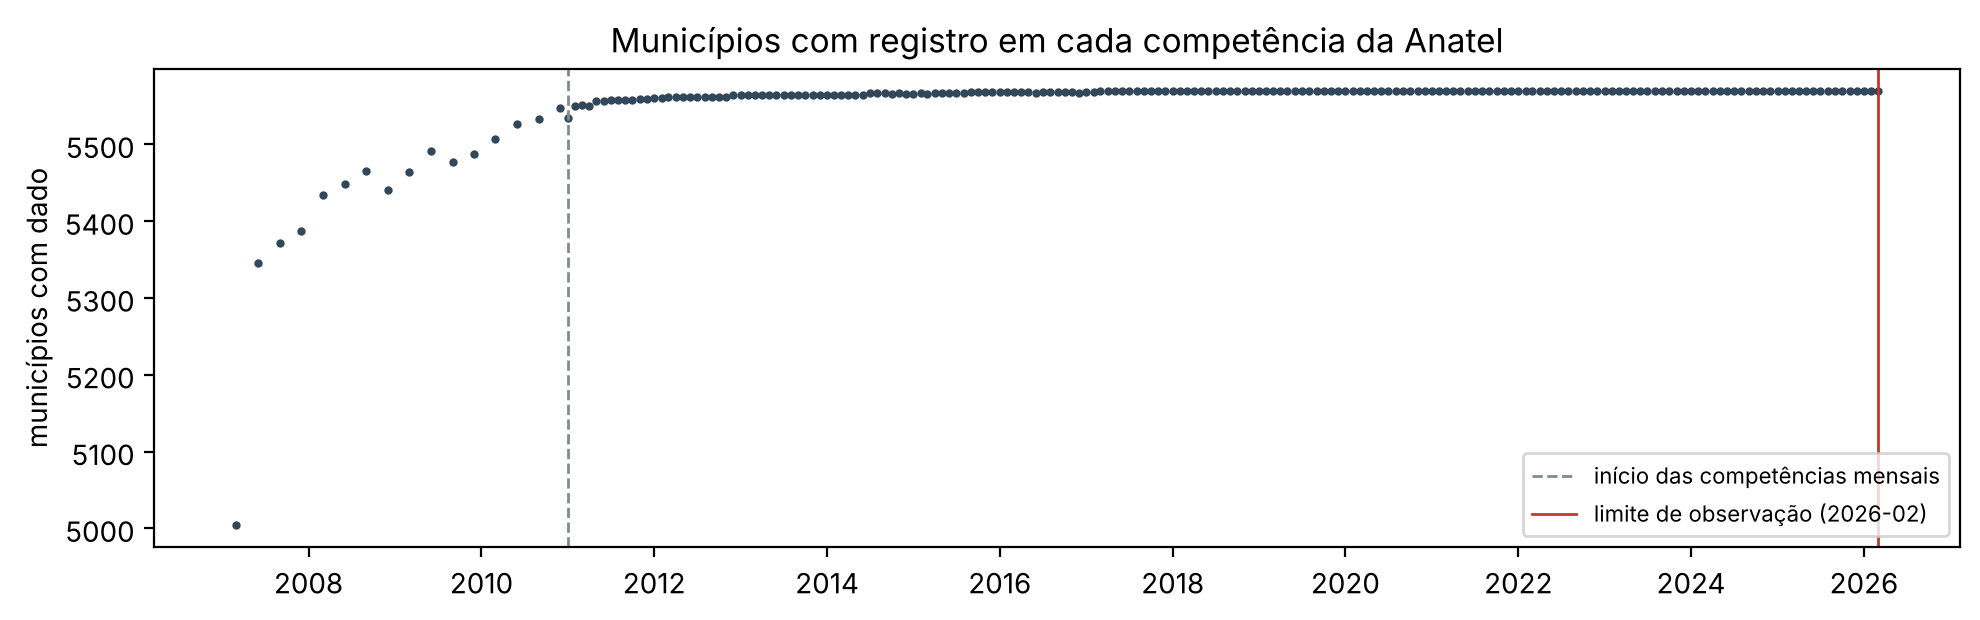

In [7]:
cobertura = PP.municipios_por_competencia(anatel_bruta)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(cobertura.index.to_timestamp(), cobertura.values, ".", ms=4, color="#33475b")
ax.axvline(pd.Timestamp(INICIO_MENSAL), color="#7f8c8d", ls="--", lw=1, label="início das competências mensais")
ax.axvline(pd.Period(LIMITE, "M").to_timestamp(how="end"), color="#c0392b", lw=1, label="limite de observação (2026-02)")
ax.set_ylabel("municípios com dado")
ax.set_title("Municípios com registro em cada competência da Anatel")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 4. Limpeza e padronização
### 4.1 Anatel: identificadores, tipos e competências
- O código do município é lido como texto e completado com zeros à esquerda até 7 dígitos.
- A densidade é mantida exatamente como publicada (ponto decimal, sem arredondamento).
- Cada registro recebe a competência (`AAAA-MM`), a periodicidade (trimestral ou mensal) e a indicação de estar dentro do limite de observação.

In [8]:
anatel = F.carregar_anatel()
anatel["competencia"] = anatel.ano.astype(str) + "-" + anatel.mes.astype(str).str.zfill(2)
anatel["periodicidade"] = PP.periodicidade(anatel.ano)
anatel["dentro_limite_observacao"] = anatel.competencia <= LIMITE

display(anatel.head(3))
anatel.groupby(["periodicidade", "dentro_limite_observacao"]).size().rename("registros").reset_index()

,ano,mes,sigla_uf,id_municipio,densidade,competencia,periodicidade,dentro_limite_observacao
0,2008,12,RO,1100098,1.715763,2008-12,trimestral,True
1,2008,12,RO,1100452,1.112784,2008-12,trimestral,True
2,2008,12,AM,1300201,0.041982,2008-12,trimestral,True


,periodicidade,dentro_limite_observacao,registros
0,mensal,False,5570
1,mensal,True,1013271
2,trimestral,True,86929


### 4.2 Organização município × mês e observações ausentes
Os registros são organizados numa grade **município × mês do calendário**. A montagem recusa registros duplicados ou meses inválidos, em vez de sobrescrever valores.

Nos anos trimestrais, os meses sem publicação ficam vazios por definição e **não** são tratados como ausências. A partir de 2011, uma competência sem registro é uma **observação ausente**: ela é identificada e listada, mas **não é preenchida** (nem com zero, nem por interpolação). Uma observação ausente não é um registro excluído: ela nunca existiu no arquivo original.

In [9]:
ids, uf, meses, M = AN.montar_matriz(anatel)
ausentes = PP.meses_ausentes(anatel)

print(f"Grade: {M.shape[0]} municípios × {M.shape[1]} meses ({meses[0]} a {meses[-1]})")
print(f"Observações mensais ausentes (2011-01 a {LIMITE}): {len(ausentes)} em "
      f"{ausentes.id_municipio.nunique()} municípios")
ausentes.groupby("sigla_uf").size().rename("meses ausentes").sort_values(ascending=False).to_frame().T

Grade: 5570 municípios × 231 meses (2007-01 a 2026-03)
Observações mensais ausentes (2011-01 a 2026-02): 160 em 34 municípios


sigla_uf,PI,PA,MA,PB,RS,TO,RR,SC,MG,AM,BA,AC,SP
meses ausentes,36,34,30,16,12,10,6,5,4,3,2,1,1


### 4.3 IBGE: conversão dos valores e união das tabelas
O SIDRA usa símbolos no lugar de números: `-` significa **zero absoluto** (convertido para 0) e `X`, `..` e `...` indicam valor inexistente ou não disponível (convertidos para ausente). Os números usam vírgula decimal e ponto de milhar.

As cinco tabelas são unidas pelo código do município. Quatro proporções são calculadas a partir das contagens.

In [10]:
tabelas, simbolos = {}, {}
for k in PP.TABELAS_IBGE:
    tabelas[k], simbolos[k] = F.carregar_sidra(k)
display(PP.simbolos_sidra(simbolos))

ibge = PP.montar_base_ibge(tabelas, anatel)
print(f"Base IBGE: {ibge.shape[0]} municípios × {ibge.shape[1]} colunas | valores ausentes: {int(ibge.isna().sum().sum())}")
ibge.head(3)

,tabela,coluna,simbolo,ocorrencias,tratamento
0,ibge_9923,pop_rural,-,32,zero
1,ibge_6805,dom_rede_ou_fossa_ligada,-,25,zero
2,ibge_6805,dom_sem_banheiro,-,1529,zero


Base IBGE: 5570 municípios × 21 colunas | valores ausentes: 0


,id_municipio,municipio,pop_total,pop_urbana,pop_rural,ind_envelhecimento,idade_mediana,razao_sexo,dom_total,dom_rede_ou_fossa_ligada,dom_sem_banheiro,moradores_renda,renda_media,renda_mediana,pop_2anos_mais,pop_com_deficiencia,pct_rural,pct_esgoto_rede_ou_fossa_ligada,pct_sem_banheiro,pct_deficiencia,sigla_uf
0,1100015,Alta Floresta D'Oeste (RO),21494,12971,8523,44.61,34,101.82,7695,36,11,21447,1210.60,920.00,20889,1432,0.396529,0.004678,0.001429,0.068553,RO
1,1100023,Ariquemes (RO),96833,83952,12881,34.61,32,98.25,34768,693,10,96129,1458.57,1066.67,94292,5956,0.133023,0.019932,0.000288,0.063165,RO
2,1100031,Cabixi (RO),5351,2846,2505,64.14,38,102.15,1967,31,0,5344,1323.79,1033.33,5245,292,0.468137,0.015760,0.000000,0.055672,RO


### 4.4 Consistência dos identificadores entre as fontes

In [11]:
PP.verificar_identificadores(anatel, tabelas)

,verificacao,resultado
0,Anatel: códigos com 7 dígitos,True
1,Anatel: municípios distintos,5570
2,Anatel: cada município com uma única UF,True
3,Anatel: prefixo do código (2 dígitos) correspo...,True
4,"Anatel: registros duplicados (município, ano, ...",0
5,ibge_9923: mesmo conjunto de municípios da Anatel,True
6,ibge_9515: mesmo conjunto de municípios da Anatel,True
7,ibge_6805: mesmo conjunto de municípios da Anatel,True
8,ibge_10295: mesmo conjunto de municípios da An...,True
9,ibge_10125: mesmo conjunto de municípios da An...,True


## 5. Qualidade dos dados e anomalias
A série da Anatel tem variações bruscas que podem ser mudanças reais ou problemas de registro. Elas são **sinalizadas, nunca corrigidas**. Uma sinalização indica um comportamento estatisticamente atípico, **não um erro comprovado da fonte**.

**Método (regra D).** A partir de 2011, cada mês é comparado com uma referência histórica: a mediana de até 6 observações válidas nos 12 meses anteriores (mínimo 3).
- **Entrada:** o mês é sinalizado quando se afasta da referência pelo menos **K = 5 vezes** e pelo menos **A = 10** acessos por 100 domicílios. Nas quedas, exige-se também referência de pelo menos 5.
- **Persistência:** se o desvio continuar por **L = 12 meses**, passa a ser tratado como um novo patamar.

**Duas leituras da mesma regra**
- **Causal (`flag_causal`):** decide com dados até o próprio mês. É a única que pode ser usada para construir features.
- **Retrospectiva (`retro_*`):** usa os meses seguintes para ver se o valor voltou e classificar o episódio. Serve para auditoria e não deve ser usada como feature.

**Evento coletivo:** episódios que começam num mês em que muitos municípios mudam ao mesmo tempo (acima do percentil 95 dos meses e de 10 inícios) são marcados à parte. Nesses casos, uma causa comum é mais provável que um problema local, e nenhuma correção automática se aplica.

**Configuração.** No pacote técnico da Etapa 1.5, as saídas principais usam K=5, A=10, L=12. L=6 foi indicado como alternativa provisória, ainda não homologada. Este notebook segue a mesma referência e calcula L=6 apenas como sensibilidade (`flag_causal_L6`). Nenhuma diferença em relação ao pacote técnico.

Nenhum valor é substituído e nenhum município é excluído.

In [12]:
# análise retrospectiva (episódios) — até o limite de observação
ep, _, _ = AN.rodar(M, meses, ids, uf, PARAMS)
ep_L6, _, _ = AN.rodar(M, meses, ids, uf, PARAMS_L6)
reg_log = AN.log_registros(ep, M, meses, PARAMS)

# sinalização causal — cada mês usa apenas meses anteriores ou o próprio mês
F12, B12 = S.sinalizar_causal(M, meses, PARAMS)
F6, _ = S.sinalizar_causal(M, meses, PARAMS_L6)

series_tab = S.construir_series(anatel, reg_log, ids, meses, PARAMS)
indicadores = PP.montar_indicadores(
    series_tab,
    PP.flags_em_tabela(F12, B12, ids, meses),
    PP.flags_em_tabela(F6, None, ids, meses, nome_flag="flag_causal_L6"),
    PP.obs_validas_12m(M, ids, meses),
    reg_log,
)
PP.resumo_sinalizacoes(indicadores, ep, ep_L6)

,indicador,tipo,registros,municipios
0,Suspeita estatística aberta (flag_causal = ±1),causal,5015,644
1,Persistência reconhecida após L meses (flag_ca...,causal,239,221
2,Referência histórica insuficiente (< 3 obs. em...,causal,106,49
3,Em episódio da análise retrospectiva,retrospectivo,5265,644
4,dos quais em mês de evento coletivo,retrospectivo,1031,188
5,dos quais suspeita individual (fora de event...,retrospectivo,4234,528
6,Sensibilidade L = 6: suspeita aberta (flag_cau...,causal,3377,644
7,"Episódios retrospectivos (K=5, A=10, L=12) | (...",retrospectivo,1029 | 1044,644 | 644


## 6. Resultado do pré-processamento
A base temporal tratada mantém **todos os registros do arquivo original**, com três versões da densidade:
- `densidade_original`: o valor publicado pela Anatel;
- `densidade_retro`: reservada a tratamentos retrospectivos de auditoria;
- `densidade_causal`: reservada às features.

Como nenhuma correção foi aprovada, as três são iguais nesta versão. As sinalizações ficam numa base separada de indicadores, com as mesmas linhas.

In [13]:
base_anatel = series_tab.drop(columns=["retro_episodio_id", "retro_classificacao"])
base_anatel = base_anatel[["id_municipio", "sigla_uf", "ano", "mes", "competencia", "periodicidade",
                           "dentro_limite_observacao", "densidade_original", "densidade_retro", "status_retro",
                           "densidade_causal", "status_causal"]]

chave = ["id_municipio", "ano", "mes"]
original_preservada = (base_anatel.sort_values(chave).densidade_original.reset_index(drop=True)
                       .equals(anatel_bruta.assign(id_municipio=F.padronizar_id(anatel_bruta.id_municipio))
                               .sort_values(chave).densidade.reset_index(drop=True)))
fmt = lambda n: f"{n:,}".replace(",", ".")   # separador de milhar brasileiro

pd.DataFrame([
    ("Registros da Anatel", fmt(len(anatel_bruta)), fmt(len(base_anatel)), "nenhum registro excluído"),
    ("Municípios (Anatel)", fmt(anatel_bruta.id_municipio.nunique()), fmt(base_anatel.id_municipio.nunique()), ""),
    ("Intervalo temporal", "2007-03 a 2026-03", f"2007-03 a {LIMITE} no processamento",
     f"{fmt(int((~base_anatel.dentro_limite_observacao).sum()))} registros de 2026-03 mantidos só para auditoria"),
    ("Densidade original preservada", "—", "sim" if original_preservada else "NÃO", "comparada registro a registro com o arquivo bruto"),
    ("Observações mensais ausentes", "—", len(ausentes), "identificadas, não preenchidas"),
    ("Registros com sinalização causal (±1 ou ±2)", "—", fmt(int(indicadores.flag_causal.fillna(0).ne(0).sum())), "valores não alterados"),
    ("Registros em episódios retrospectivos", "—", fmt(int(indicadores.retro_suspeita.sum())), "só auditoria"),
    ("Duplicidades (município, competência)", int(anatel_bruta.duplicated(["id_municipio", "ano", "mes"]).sum()),
     int(base_anatel.duplicated(["id_municipio", "competencia"]).sum()), ""),
    ("Municípios (IBGE)", f"{fmt(len(sidra_brutas['ibge_9923']))} em cada uma das 5 tabelas", fmt(len(ibge)), "mesmos códigos da Anatel"),
    ("Colunas (IBGE)", "5 tabelas × 5 colunas", ibge.shape[1], "inclui 4 proporções e a UF"),
], columns=["item", "dados brutos", "bases tratadas", "observação"])

,item,dados brutos,bases tratadas,observação
0,Registros da Anatel,1.105.770,1.105.770,nenhum registro excluído
1,Municípios (Anatel),5.570,5.570,
2,Intervalo temporal,2007-03 a 2026-03,2007-03 a 2026-02 no processamento,5.570 registros de 2026-03 mantidos só para au...
3,Densidade original preservada,—,sim,comparada registro a registro com o arquivo bruto
4,Observações mensais ausentes,—,160,"identificadas, não preenchidas"
5,Registros com sinalização causal (±1 ou ±2),—,5.254,valores não alterados
6,Registros em episódios retrospectivos,—,5.265,só auditoria
7,"Duplicidades (município, competência)",0,0,
8,Municípios (IBGE),5.570 em cada uma das 5 tabelas,5.570,mesmos códigos da Anatel
9,Colunas (IBGE),5 tabelas × 5 colunas,21,inclui 4 proporções e a UF


## 7. Exportação das bases tratadas
As bases são gravadas em `dados_tratados/`. O painel de modelagem, as features e o alvo de 36 meses **não** são criados aqui.

| Arquivo | Finalidade |
|---|---|
| `anatel_densidade_tratada.csv` | Base temporal da Anatel: um registro por município e competência, com as três versões da densidade |
| `anatel_indicadores_qualidade.csv` | Sinalizações causais (inclusive L=6) e retrospectivas, evento coletivo e referência insuficiente, por registro |
| `anatel_meses_ausentes.csv` | Competências mensais sem registro no arquivo original |
| `ibge_municipal_2022_tratada.csv` | Base municipal do Censo 2022 |
| `dicionario_bases_tratadas.csv` | Descrição de cada coluna das bases acima |

Na etapa seguinte, as features só podem usar `densidade_causal` e as colunas causais dos indicadores. As colunas `retro_*` usam informação de meses posteriores.

In [14]:
exportados = PP.exportar({
    "anatel_densidade_tratada.csv": base_anatel,
    "anatel_indicadores_qualidade.csv": indicadores,
    "anatel_meses_ausentes.csv": ausentes,
    "ibge_municipal_2022_tratada.csv": ibge,
    "dicionario_bases_tratadas.csv": PP.dicionario(),
})
exportados

,arquivo,linhas,colunas,tamanho_mb,sha256
0,dados_tratados/anatel_densidade_tratada.csv,1105770,12,131.4,0580faf6fc488b97
1,dados_tratados/anatel_indicadores_qualidade.csv,1105770,13,60.8,767c05bf8e524016
2,dados_tratados/anatel_meses_ausentes.csv,160,3,0.0,5a3dae2b85f0189d
3,dados_tratados/ibge_municipal_2022_tratada.csv,5570,21,1.0,7114dceeeab075cf
4,dados_tratados/dicionario_bases_tratadas.csv,39,4,0.0,66812b9812bb3d8b


## 8. Conferência final
Verificações de reprodutibilidade:
- os dados brutos não mudaram durante a execução;
- os resultados coincidem com os do pacote técnico da Etapa 1.5 (`auditoria_tecnica/`);
- as flags causais não dependem de meses posteriores;
- março de 2026 não entra no processamento principal.

In [15]:
hash_fim = PP.hashes_brutos()
display(pd.DataFrame([("Dados brutos inalterados durante a execução (SHA-256)", hash_inicio.equals(hash_fim))],
                     columns=["conferencia", "resultado"]))
PP.conferir_com_etapa_1_5(ep, reg_log, ep_L6, ausentes, hash_inicio)

,conferencia,resultado
0,Dados brutos inalterados durante a execução (S...,True


,conferencia,resultado
0,Dados brutos com o mesmo SHA-256 registrado na...,True
1,"Episódios (K=5, A=10, L=12): mesmos episódios ...",True
2,Registros em episódios: mesmos registros e cla...,True
3,Episódios com L=6 (sensibilidade): mesmos epis...,True
4,Meses ausentes: mesma contagem,True


**Limite temporal das flags causais.** A sinalização é recalculada usando só os dados até cada data e comparada com a sinalização completa. Se forem idênticas, nenhum mês posterior influenciou o resultado.

In [16]:
display(PP.conferir_limite_causal(M, meses, PARAMS, F12))

marco = indicadores[~indicadores.dentro_limite_observacao]
pd.Series({
    "último mês com flag causal": str(meses[F12.shape[1] - 1]),
    "registros de 2026-03 com flag causal": int(marco.flag_causal.notna().sum()),
    "registros de 2026-03 em episódios retrospectivos": int(marco.retro_suspeita.sum()),
    "último mês de episódio retrospectivo": ep.fim.max(),
}, name="valor").to_frame()

,dados_ate,flags_identicas_ate_a_data
0,2016-06,True
1,2021-01,True
2,2025-06,True


,valor
último mês com flag causal,2026-02
registros de 2026-03 com flag causal,0
registros de 2026-03 em episódios retrospectivos,0
último mês de episódio retrospectivo,2026-02


**Limitações.** As sinalizações são estatísticas e não confirmam erros da Anatel. As 160 observações ausentes não foram preenchidas. Os parâmetros da regra D e a política de tratamento das observações sinalizadas ainda dependem de homologação do grupo antes da modelagem (ver `auditoria_tecnica/`).